# P1 — Perfil da base de graduação
Análise de cada variável isoladamente. As linhas representam aluno, semestre e currículo; um aluno pode aparecer mais de uma vez. As estatísticas acadêmicas usam somente linhas ACADEMICA. Dados financeiros e socioeconômicos não estão disponíveis, limitando a interpretação.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
raiz = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(raiz))
from src.dados import carregar_base
from src.eventos import filtrar_graduacao, marcar_evento_saida, consolidar_aluno_semestre, tabela_por_aluno
figuras = raiz / 'reports' / 'figures'
figuras.mkdir(parents=True, exist_ok=True)
base = filtrar_graduacao(carregar_base())
academica = base.loc[base.ORIGEMREGISTRO.eq('ACADEMICA')].copy()
academica.loc[academica.IA04_01 > 100, 'IA04_01'] = np.nan
academica['APROVEIT'] = academica.APROVEIT.fillna(0)
academica['PROGRESSO_OBRIGATORIAS'] = academica.IA75_02 / academica.IA75_01.where(academica.IA75_01 > 0)
alunos = tabela_por_aluno(consolidar_aluno_semestre(marcar_evento_saida(base)))
print('Base de graduação carregada.')


Base de graduação carregada.


## Indicadores numéricos
Unidade: linhas acadêmicas. A frequência acima de 100% é nula; APROVEIT vazio é zero. Progresso é nulo quando o total de obrigatórias é zero ou ausente. A regra de valores atípicos usa 1,5 intervalo interquartil.

Os extremos são suprimidos quando representam menos de 10 alunos. PERIODO zero fora de GAE é mantido, mas seu significado ainda precisa ser esclarecido.


In [2]:
variaveis = {
'CRENOSEMESTRE': ('CRE no semestre', 'pontos'),
'CREATESEMESTRE': ('CRE até o semestre', 'pontos'),
'MEDIANAATESEMESTRE': ('Mediana até o semestre', 'pontos'),
'IA04_01': ('Frequência', '%'),
'IA04_02': ('Disciplinas com mais de 25% de faltas', 'disciplinas'),
'IA75_04': ('Disciplinas matriculadas', 'disciplinas'),
'IA75_03': ('Disciplinas aprovadas', 'disciplinas'),
'IA34_03': ('Disciplinas reprovadas', 'disciplinas'),
'IA65_03': ('Disciplinas retiradas', 'disciplinas'),
'PROGRESSO_OBRIGATORIAS': ('Obrigatórias concluídas / grade', 'proporção'),
'IA75_05': ('Obrigatórias previstas para o período', 'disciplinas'),
'ATIVCOMPL_MATRICULADAS': ('Atividades complementares matriculadas', 'atividades'),
'ATIVCOMPL_APROVADAS': ('Atividades complementares aprovadas', 'atividades'),
'ATIVCOMPL_REPROVADAS': ('Atividades complementares reprovadas', 'atividades'),
'PERIODO': ('Período', 'período'),
'APROVEIT': ('Semestres aproveitados', 'semestres')}
estat = academica[list(variaveis)].describe().T.rename(columns={'count':'n (linhas)','mean':'média','std':'desvio-padrão','min':'mínimo','25%':'Q1','50%':'mediana','75%':'Q3','max':'máximo'})
for col in variaveis:
    if academica.loc[academica[col].notna(), 'HANDLEALUNO'].nunique() < 10:
        estat.loc[col] = np.nan
# Cada extremo é protegido segundo o número de alunos que o apresentam.
estat = estat.round(2).astype(object)
for col in variaveis:
    valores = academica[col].dropna()
    if len(valores):
        for nome, extremo in [('mínimo', valores.min()), ('máximo', valores.max())]:
            pessoas = academica.loc[academica[col].eq(extremo), 'HANDLEALUNO'].nunique()
            if pessoas < 10:
                estat.loc[col, nome] = 'suprimido'
display(estat)


,n (linhas),média,desvio-padrão,mínimo,Q1,mediana,Q3,máximo
CRENOSEMESTRE,42452.0,57.92,23.15,0.0,44.8,62.33,75.14,100.0
CREATESEMESTRE,43253.0,57.36,19.84,0.0,47.08,59.93,71.23,suprimido
MEDIANAATESEMESTRE,42444.0,61.66,19.1,0.0,55.0,65.0,74.0,100.0
IA04_01,42279.0,90.88,9.38,suprimido,88.0,93.45,96.85,100.0
IA04_02,42281.0,0.24,0.8,0.0,0.0,0.0,0.0,suprimido
IA75_04,44393.0,5.61,1.88,0.0,4.0,6.0,7.0,suprimido
IA75_03,44393.0,3.75,2.35,0.0,2.0,4.0,6.0,suprimido
IA34_03,44393.0,1.13,1.55,0.0,0.0,0.0,2.0,suprimido
IA65_03,44393.0,0.35,0.86,0.0,0.0,0.0,0.0,suprimido
PROGRESSO_OBRIGATORIAS,44393.0,0.38,0.3,0.0,0.11,0.31,0.61,1.0


**CRENOSEMESTRE — CRE no semestre:** Maior concentração em valores intermediários e altos, com cauda para valores menores. Menos da metade das linhas válidas tem valor zero; valores fora de 1,5 IIQ não são detalhados por privacidade.

C:\Users\Flavio\AppData\Local\Temp\ipykernel_10008\2841220310.py:53: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bx.boxplot(s,vert=False,showfliers=False,whis=(25,75))


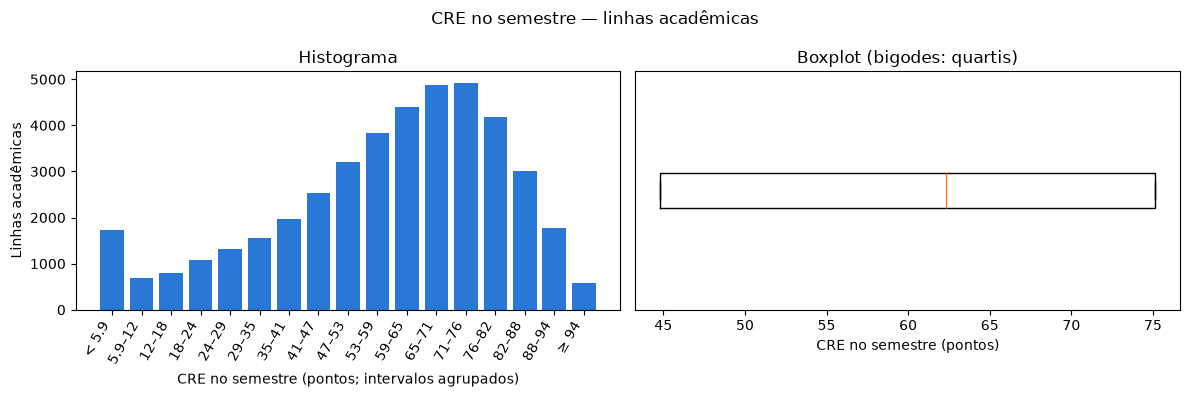

**CREATESEMESTRE — CRE até o semestre:** Maior concentração em valores intermediários e altos, com cauda para valores menores. Menos da metade das linhas válidas tem valor zero; há valores fora dos limites de 1,5 IIQ.

C:\Users\Flavio\AppData\Local\Temp\ipykernel_10008\2841220310.py:53: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bx.boxplot(s,vert=False,showfliers=False,whis=(25,75))


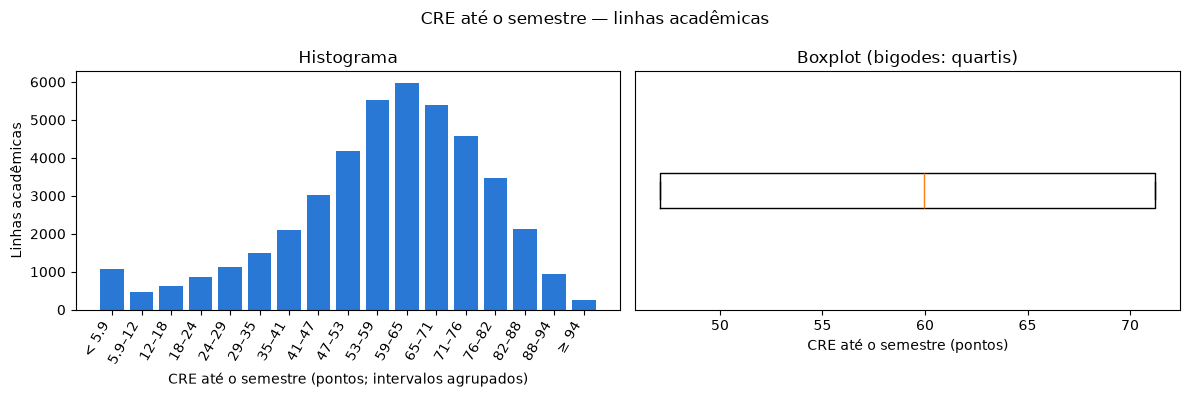

**MEDIANAATESEMESTRE — Mediana até o semestre:** Concentração em valores intermediários e altos, com cauda para valores menores. Menos da metade das linhas válidas tem valor zero; há valores fora dos limites de 1,5 IIQ.

C:\Users\Flavio\AppData\Local\Temp\ipykernel_10008\2841220310.py:53: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bx.boxplot(s,vert=False,showfliers=False,whis=(25,75))


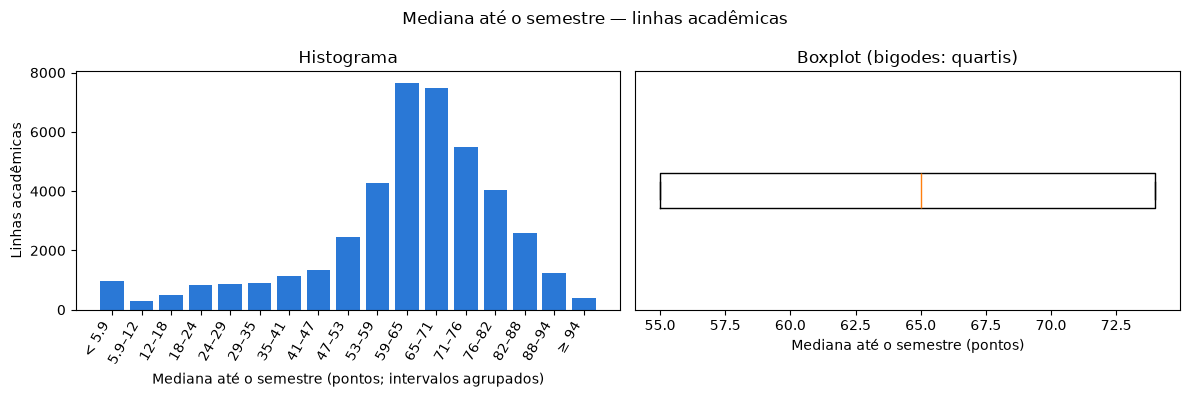

**IA04_01 — Frequência:** Frequências altas predominam, com cauda alongada para frequências menores. Menos da metade das linhas válidas tem valor zero; há valores fora dos limites de 1,5 IIQ.

C:\Users\Flavio\AppData\Local\Temp\ipykernel_10008\2841220310.py:53: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bx.boxplot(s,vert=False,showfliers=False,whis=(25,75))


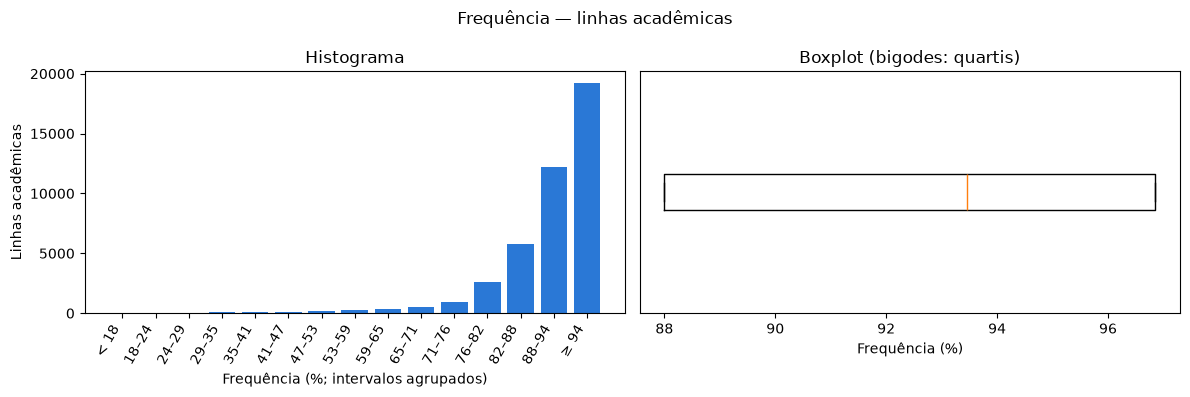

**IA04_02 — Disciplinas com mais de 25% de faltas:** Forte concentração em zero, com cauda à direita. Pelo menos metade das linhas válidas tem valor zero; há valores fora dos limites de 1,5 IIQ.

C:\Users\Flavio\AppData\Local\Temp\ipykernel_10008\2841220310.py:53: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bx.boxplot(s,vert=False,showfliers=False,whis=(25,75))


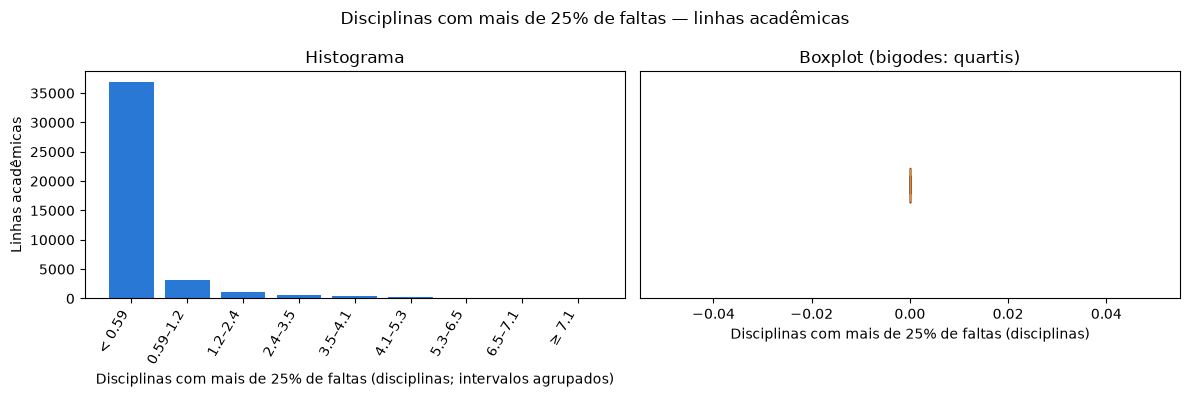

**IA75_04 — Disciplinas matriculadas:** Concentração na região central, com perfil aproximadamente equilibrado e caudas em ambos os lados. Menos da metade das linhas válidas tem valor zero; há valores fora dos limites de 1,5 IIQ.

C:\Users\Flavio\AppData\Local\Temp\ipykernel_10008\2841220310.py:53: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bx.boxplot(s,vert=False,showfliers=False,whis=(25,75))


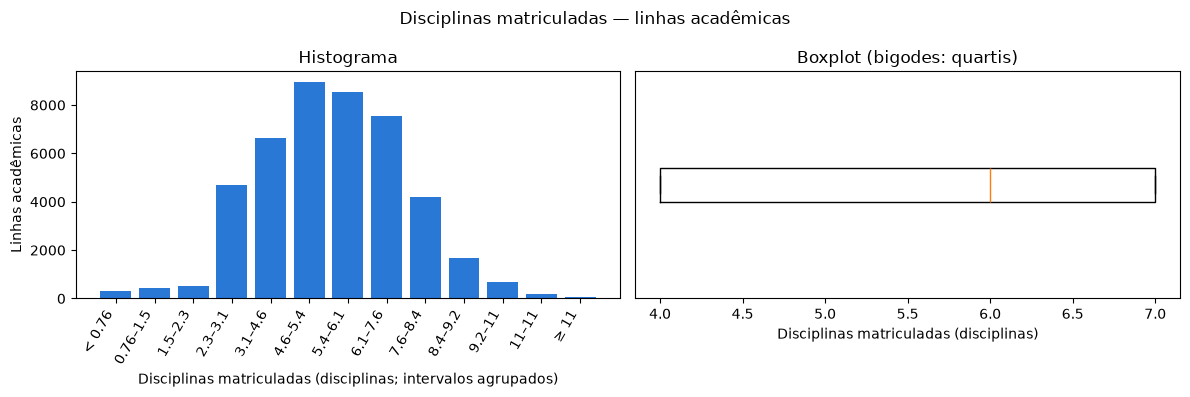

**IA75_03 — Disciplinas aprovadas:** Distribuição espalhada, com concentração em valores intermediários e presença expressiva de zeros. Menos da metade das linhas válidas tem valor zero; valores fora de 1,5 IIQ não são detalhados por privacidade.

C:\Users\Flavio\AppData\Local\Temp\ipykernel_10008\2841220310.py:53: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bx.boxplot(s,vert=False,showfliers=False,whis=(25,75))


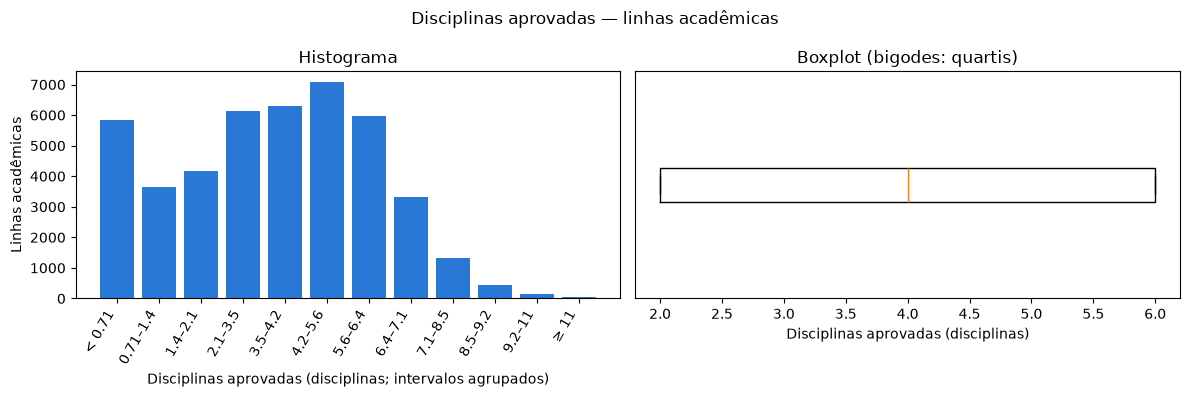

**IA34_03 — Disciplinas reprovadas:** Concentração em zero e cauda à direita. Pelo menos metade das linhas válidas tem valor zero; há valores fora dos limites de 1,5 IIQ.

C:\Users\Flavio\AppData\Local\Temp\ipykernel_10008\2841220310.py:53: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bx.boxplot(s,vert=False,showfliers=False,whis=(25,75))


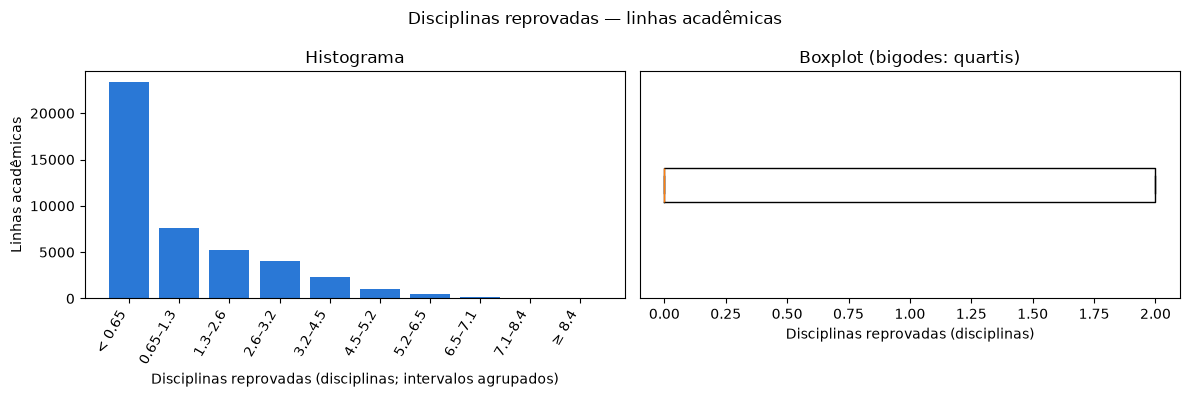

**IA65_03 — Disciplinas retiradas:** Forte concentração em zero e cauda à direita. Pelo menos metade das linhas válidas tem valor zero; há valores fora dos limites de 1,5 IIQ.

C:\Users\Flavio\AppData\Local\Temp\ipykernel_10008\2841220310.py:53: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bx.boxplot(s,vert=False,showfliers=False,whis=(25,75))


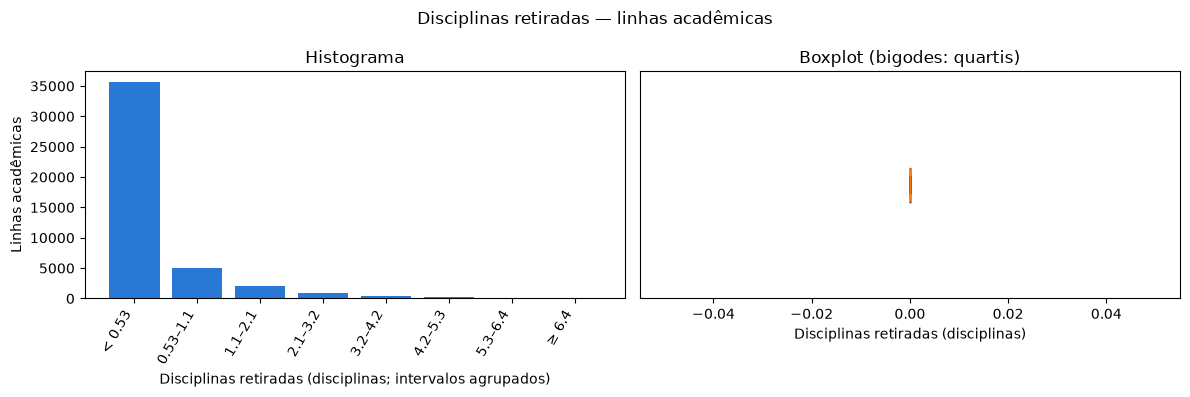

**PROGRESSO_OBRIGATORIAS — Obrigatórias concluídas / grade:** Valores baixos são mais frequentes, com distribuição espalhada e cauda para proporções maiores. Menos da metade das linhas válidas tem valor zero; valores fora de 1,5 IIQ não são detalhados por privacidade.

C:\Users\Flavio\AppData\Local\Temp\ipykernel_10008\2841220310.py:53: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bx.boxplot(s,vert=False,showfliers=False,whis=(25,75))


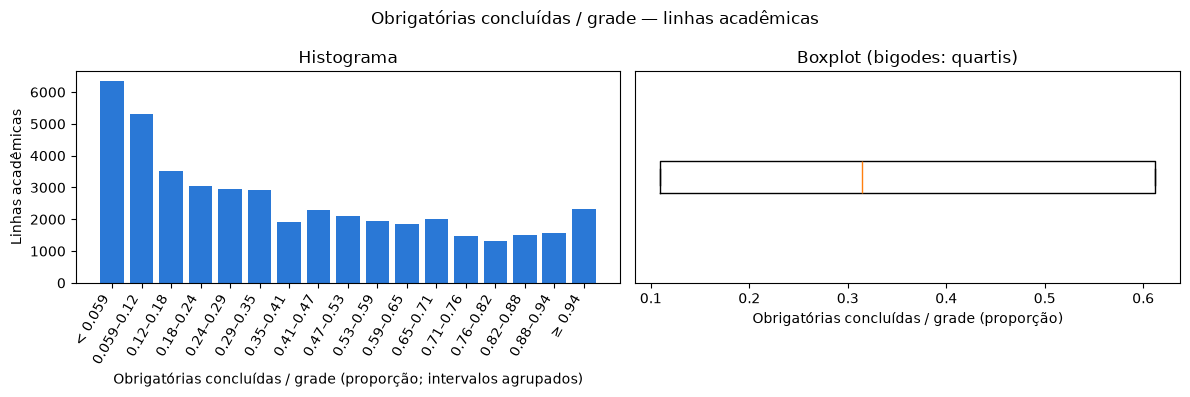

**IA75_05 — Obrigatórias previstas para o período:** Concentração em valores intermediários, com perfil aproximadamente equilibrado. Menos da metade das linhas válidas tem valor zero; há valores fora dos limites de 1,5 IIQ.

C:\Users\Flavio\AppData\Local\Temp\ipykernel_10008\2841220310.py:53: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bx.boxplot(s,vert=False,showfliers=False,whis=(25,75))


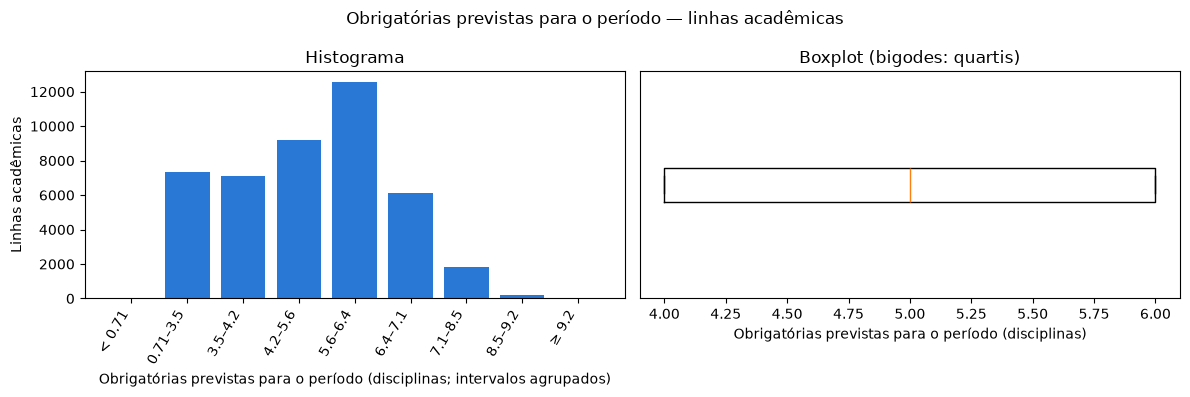

**ATIVCOMPL_MATRICULADAS — Atividades complementares matriculadas:** Concentração em zero e um, com cauda à direita. Menos da metade das linhas válidas tem valor zero; há valores fora dos limites de 1,5 IIQ.

C:\Users\Flavio\AppData\Local\Temp\ipykernel_10008\2841220310.py:53: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bx.boxplot(s,vert=False,showfliers=False,whis=(25,75))


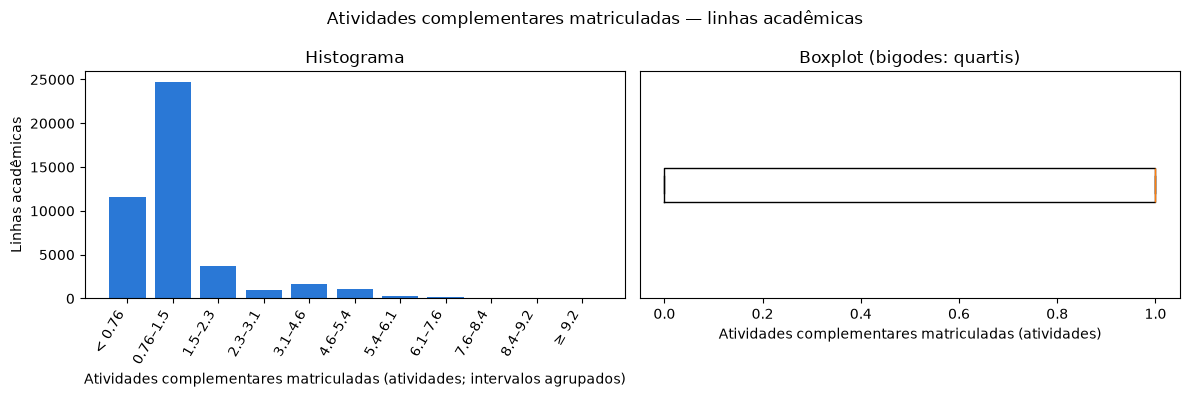

**ATIVCOMPL_APROVADAS — Atividades complementares aprovadas:** Concentração em zero e um, com cauda à direita. Menos da metade das linhas válidas tem valor zero; há valores fora dos limites de 1,5 IIQ.

C:\Users\Flavio\AppData\Local\Temp\ipykernel_10008\2841220310.py:53: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bx.boxplot(s,vert=False,showfliers=False,whis=(25,75))


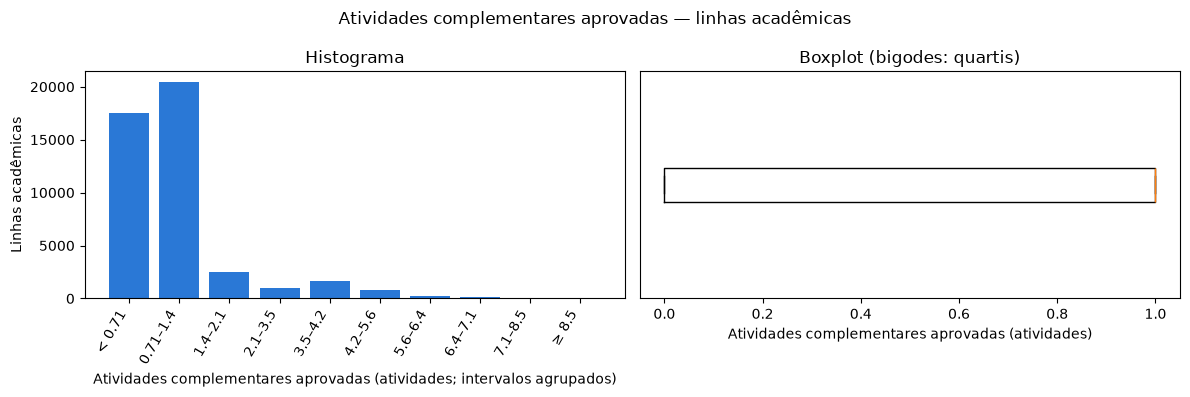

**ATIVCOMPL_REPROVADAS — Atividades complementares reprovadas:** Forte concentração em zero, com cauda à direita. Pelo menos metade das linhas válidas tem valor zero; há valores fora dos limites de 1,5 IIQ.

C:\Users\Flavio\AppData\Local\Temp\ipykernel_10008\2841220310.py:53: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bx.boxplot(s,vert=False,showfliers=False,whis=(25,75))


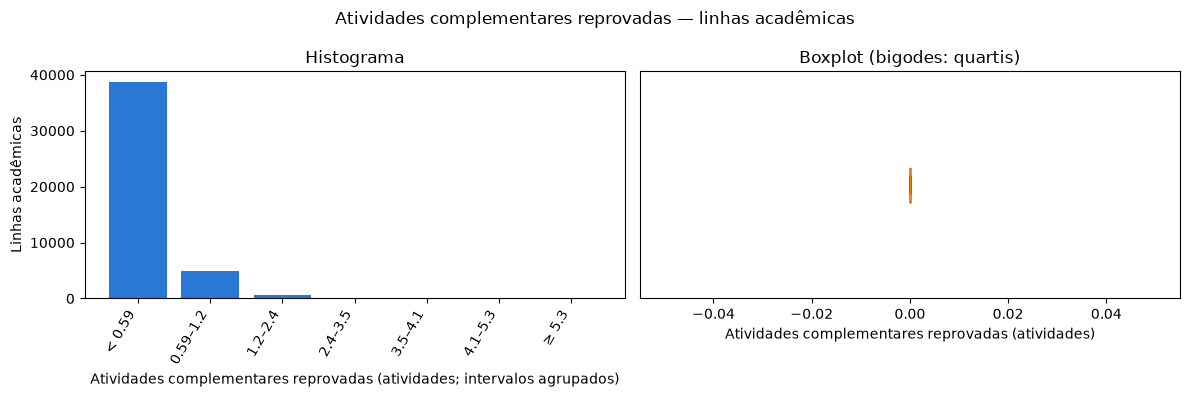

**PERIODO — Período:** Períodos iniciais são mais frequentes; a distribuição se estende para períodos maiores. Menos da metade das linhas válidas tem valor zero; valores fora de 1,5 IIQ não são detalhados por privacidade.

C:\Users\Flavio\AppData\Local\Temp\ipykernel_10008\2841220310.py:53: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bx.boxplot(s,vert=False,showfliers=False,whis=(25,75))


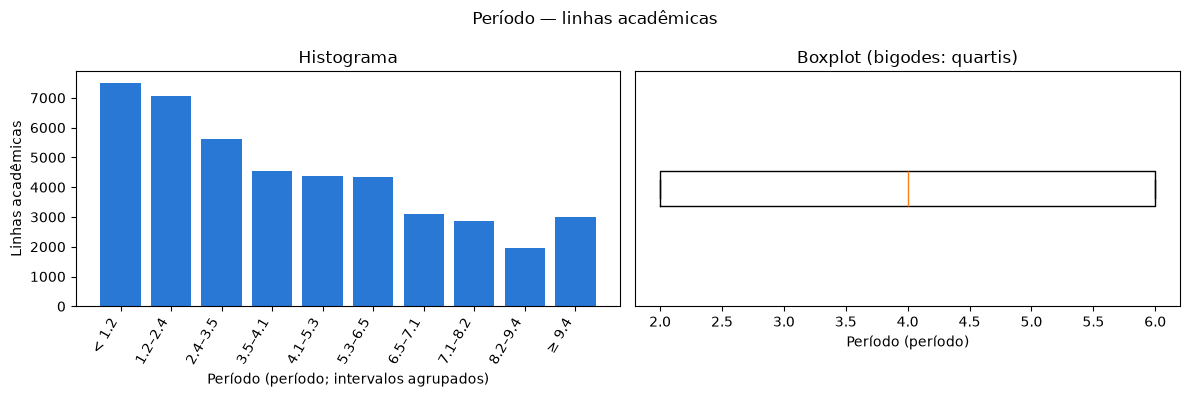

**APROVEIT — Semestres aproveitados:** Forte concentração em zero após o tratamento dos vazios, com cauda à direita. Pelo menos metade das linhas válidas tem valor zero; há valores fora dos limites de 1,5 IIQ.

C:\Users\Flavio\AppData\Local\Temp\ipykernel_10008\2841220310.py:53: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bx.boxplot(s,vert=False,showfliers=False,whis=(25,75))


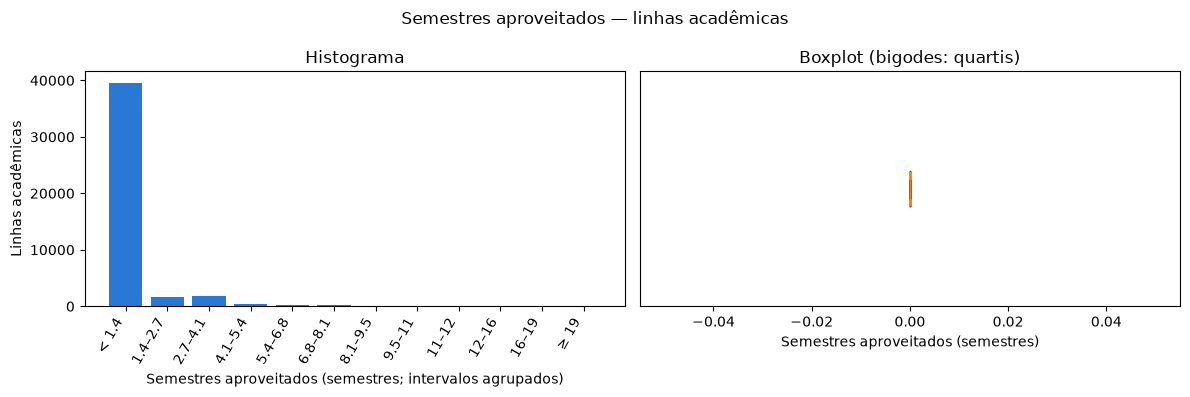

In [3]:
# Leitura dos histogramas da extração v7; revisar caso a base seja atualizada.
leituras = {
'CRENOSEMESTRE': 'Maior concentração em valores intermediários e altos, com cauda para valores menores.',
'CREATESEMESTRE': 'Maior concentração em valores intermediários e altos, com cauda para valores menores.',
'MEDIANAATESEMESTRE': 'Concentração em valores intermediários e altos, com cauda para valores menores.',
'IA04_01': 'Frequências altas predominam, com cauda alongada para frequências menores.',
'IA04_02': 'Forte concentração em zero, com cauda à direita.',
'IA75_04': 'Concentração na região central, com perfil aproximadamente equilibrado e caudas em ambos os lados.',
'IA75_03': 'Distribuição espalhada, com concentração em valores intermediários e presença expressiva de zeros.',
'IA34_03': 'Concentração em zero e cauda à direita.',
'IA65_03': 'Forte concentração em zero e cauda à direita.',
'PROGRESSO_OBRIGATORIAS': 'Valores baixos são mais frequentes, com distribuição espalhada e cauda para proporções maiores.',
'IA75_05': 'Concentração em valores intermediários, com perfil aproximadamente equilibrado.',
'ATIVCOMPL_MATRICULADAS': 'Concentração em zero e um, com cauda à direita.',
'ATIVCOMPL_APROVADAS': 'Concentração em zero e um, com cauda à direita.',
'ATIVCOMPL_REPROVADAS': 'Forte concentração em zero, com cauda à direita.',
'PERIODO': 'Períodos iniciais são mais frequentes; a distribuição se estende para períodos maiores.',
'APROVEIT': 'Forte concentração em zero após o tratamento dos vazios, com cauda à direita.'
}
def grafico_numerico(col, nome, unidade):
    dados = academica.loc[academica[col].notna(), [col,'HANDLEALUNO']].reset_index(drop=True)
    s = dados[col].astype(float)
    if dados.HANDLEALUNO.nunique() < 10:
        display(Markdown(f'**{col}:** amostra insuficiente.'))
        return
    q1, med, q3 = s.quantile([.25,.5,.75])
    fora = (s < q1-1.5*(q3-q1)) | (s > q3+1.5*(q3-q1))
    nf = dados.loc[fora, 'HANDLEALUNO'].nunique()
    zeros = (s == 0).mean()
    forma = 'pelo menos metade das linhas válidas tem valor zero' if zeros >= .5 else 'menos da metade das linhas válidas tem valor zero'
    aviso = 'há valores fora dos limites de 1,5 IIQ' if nf >= 10 else 'valores fora de 1,5 IIQ não são detalhados por privacidade'
    display(Markdown(f'**{col} — {nome}:** {leituras[col]} {forma.capitalize()}; {aviso}.'))
    edges = np.histogram_bin_edges(s, bins='sturges')
    indice = np.clip(np.searchsorted(edges,s,side='right')-1,0,len(edges)-2)
    grupos, atual = [], []
    for i in range(len(edges)-1):
        atual.extend(np.flatnonzero(indice == i))
        if atual and dados.iloc[atual].HANDLEALUNO.nunique() >= 10:
            grupos.append(atual); atual = []
    if atual and grupos: grupos[-1].extend(atual)
    if not grupos: return
    fig, (ax,bx) = plt.subplots(1,2,figsize=(12,4))
    # Mostra apenas cortes internos arredondados, ocultando os extremos.
    cortes = [float(f'{edges[indice[g[-1]]+1]:.2g}') for g in grupos[:-1]]
    if len(grupos) == 1:
        labels = ['Todos os valores']
    else:
        labels = [f'< {cortes[0]:.2g}'] + [f'{cortes[i-1]:.2g}–{cortes[i]:.2g}' for i in range(1,len(cortes))] + [f'≥ {cortes[-1]:.2g}']
    ax.bar(range(len(grupos)),[len(g) for g in grupos],color='#2a78d6')
    ax.set_xticks(range(len(grupos)),labels,rotation=60,ha='right')
    ax.set_xlabel(f'{nome} ({unidade}; intervalos agrupados)')
    ax.set_ylabel('Linhas acadêmicas'); ax.set_title('Histograma')
    bx.boxplot(s,vert=False,showfliers=False,whis=(25,75))
    bx.set_xlabel(f'{nome} ({unidade})'); bx.set_yticks([])
    bx.set_title('Boxplot (bigodes: quartis)')
    fig.suptitle(nome + ' — linhas acadêmicas')
    fig.tight_layout(); fig.savefig(figuras / f'04_{col.lower()}.png',dpi=150,bbox_inches='tight'); plt.show()
for col,(nome,unidade) in variaveis.items():
    grafico_numerico(col,nome,unidade)


## Categóricas
Curso e turno usam o primeiro semestre observado, e sexo usa o primeiro valor não nulo; essas contagens são por aluno. Status e origem são contados por linha. Categorias com menos de 10 alunos são agrupadas em Outros; quando necessário outra categoria é adicionada para proteger o grupo.


,alunos,%
SIGLACURSO,,
GEC,1866,24.6
GET,1418,18.7
GEA,989,13.0
GEB,888,11.7
GES,776,10.2
TAI,547,7.2
GEE,472,6.2
TGT,239,3.1
GEP,174,2.3


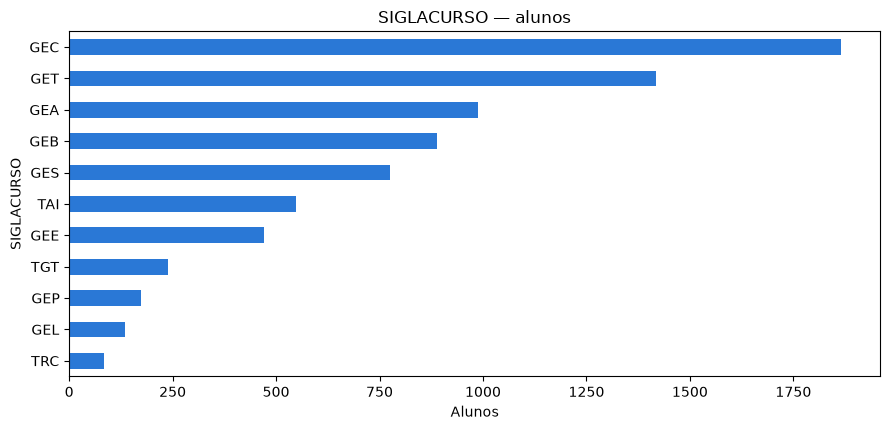

,alunos,%
TURNO,,
Integral,5636,74.3
Noturno,1953,25.7


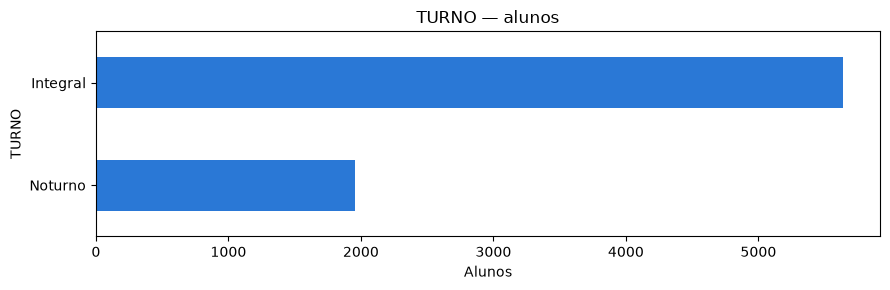

,alunos,%
SEXO,,
M,5908,77.8
Outros,1681,22.2


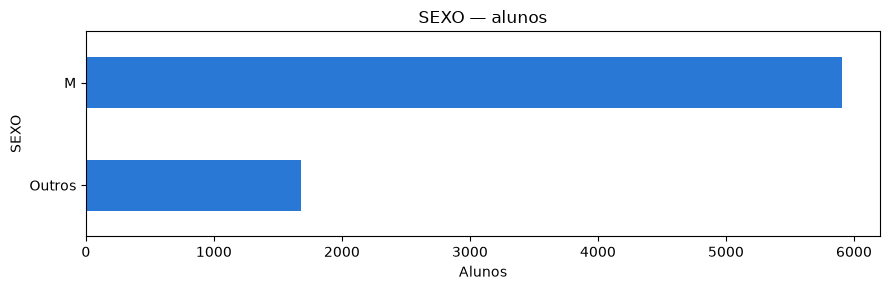

,linhas,%
STATUSALUNO,,
Ativo,42119,71.3
Desconhecido,11351,19.2
Inativo,4819,8.2
Matrícula Pendente,679,1.2
Outros,64,0.1


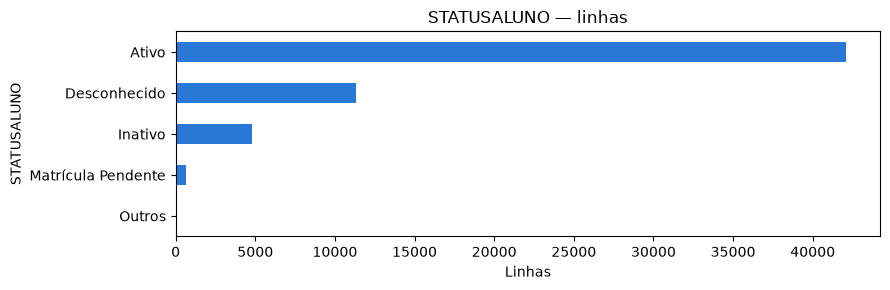

,linhas,%
ORIGEMREGISTRO,,
ACADEMICA,44393,75.2
OCORRENCIA,14639,24.8


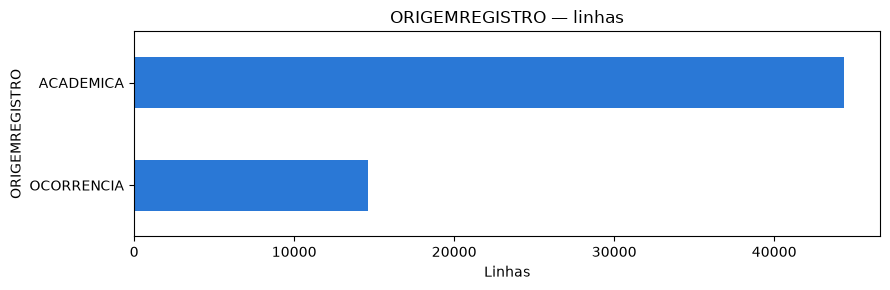

In [4]:
def categorias(col, por_aluno):
    if por_aluno:
        tab = alunos[[col]].copy()
        tab['_pessoa'] = tab.index
    else:
        tab = base[[col,'HANDLEALUNO']].rename(columns={'HANDLEALUNO':'_pessoa'}).copy()
    tab[col] = tab[col].astype('string').fillna('Não informado')
    pessoas = tab.groupby(col)['_pessoa'].nunique()
    pequenos = set(pessoas[pessoas < 10].index)
    if pequenos:
        while tab.loc[tab[col].isin(pequenos),'_pessoa'].nunique() < 10:
            restantes = pessoas.drop(index=list(pequenos),errors='ignore')
            if restantes.empty: break
            pequenos.add(restantes.idxmin())
        tab[col] = tab[col].where(~tab[col].isin(pequenos),'Outros')
    cont = tab[col].value_counts()
    unidade = 'alunos' if por_aluno else 'linhas'
    resultado = pd.DataFrame({unidade:cont, '%':(cont/cont.sum()*100).round(1)})
    resultado.index.name = col
    display(resultado)
    ax = resultado[unidade].sort_values().plot.barh(figsize=(9,max(3,len(cont)*.4)),color='#2a78d6')
    ax.set_xlabel(unidade.capitalize()); ax.set_ylabel(col); ax.set_title(f'{col} — {unidade}')
    plt.tight_layout(); plt.savefig(figuras / f'04_{col.lower()}.png',dpi=150,bbox_inches='tight'); plt.show()
    return resultado
categoricas = {}
for col in ['SIGLACURSO','TURNO','SEXO','STATUSALUNO','ORIGEMREGISTRO']:
    categoricas[col] = categorias(col,col in ['SIGLACURSO','TURNO','SEXO'])


## Ano de ingresso
Contagem de alunos pelo ano de ingresso no primeiro vínculo. INGRESSO representa entrada no currículo, não forma de admissão.

O ano de 2026 é parcial: a base termina no primeiro semestre. Não compare seu total diretamente com anos completos.


,alunos
INGRESSO,
2009,336
2010,424
2011,563
2012,581
2013,651
2014,607
2015,456
2016,375
2017,319


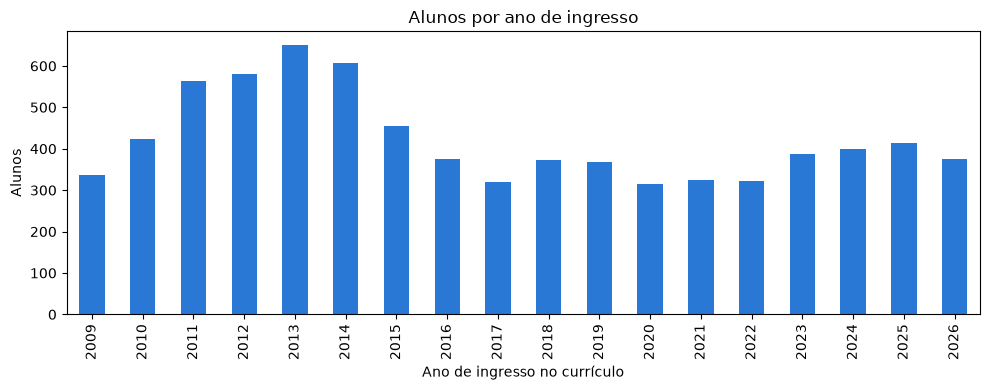

In [5]:
ano = alunos.INGRESSO.astype('string').str[:4].fillna('Não informado')
ano = ano.where(ano.map(ano.value_counts()) >= 10,'Outros')
if 0 < (ano == 'Outros').sum() < 10:
    menor = ano[ano != 'Outros'].value_counts().idxmin()
    ano = ano.where(ano != menor,'Outros')
ingresso = ano.value_counts().sort_index().rename('alunos').to_frame()
display(ingresso)
ax = ingresso.plot.bar(legend=False,figsize=(10,4),color='#2a78d6')
ax.set_xlabel('Ano de ingresso no currículo'); ax.set_ylabel('Alunos'); ax.set_title('Alunos por ano de ingresso')
plt.tight_layout(); plt.savefig(figuras / '04_ingresso_ano.png',dpi=150,bbox_inches='tight'); plt.show()


## Flags de ocorrência
Linhas e alunos distintos com flag igual a 1. Uma pessoa pode aparecer em várias flags. TEVECONCLUSAOPROGRAMA é excluída por não ter ocorrências. Grupos com menos de 10 alunos são suprimidos.


In [6]:
flags = [c for c in base if c.startswith('TEVE') and c != 'TEVECONCLUSAOPROGRAMA']
registros = []
for flag in flags:
    mask = base[flag].eq(1)
    n = base.loc[mask,'HANDLEALUNO'].nunique()
    registros.append({'Flag':flag, 'Linhas':int(mask.sum()) if n >= 10 or n == 0 else 'menos de 10', 'Alunos distintos':int(n) if n >= 10 or n == 0 else 'menos de 10'})
display(pd.DataFrame(registros).set_index('Flag'))


,Linhas,Alunos distintos
Flag,,
TEVEDESISTENCIA,2311,2182
TEVEABANDONO,760,658
TEVETRANCAMENTO,1727,956
TEVECANCELAMENTO,766,756
TEVEDESLIGAMENTO,menos de 10,menos de 10
TEVETRANSAFASTAMENTO,325,323
TEVEDIPLOMACAO,2644,2634
TEVEREINGRESSO,253,140
TEVEMUDANCACURSO,892,833


## Observações principais
Calculadas nas células executadas. Os indicadores se referem às linhas acadêmicas válidas; as categorias usam alunos.


In [7]:
obs = []
obs.append(f'O recorte contém {len(base)} linhas e {len(alunos)} alunos distintos.')
obs.append(f'Das linhas do recorte, {len(academica)/len(base)*100:.1f}% são acadêmicas.')
for col in ['CRENOSEMESTRE','IA04_01','IA75_04','PROGRESSO_OBRIGATORIAS']:
    s = academica[col].dropna()
    if len(s) and academica.loc[s.index,'HANDLEALUNO'].nunique() >= 10:
        obs.append(f'{variaveis[col][0]}: mediana de {s.median():.2f} {variaveis[col][1]} em {len(s)} linhas válidas.')
for col in ['SIGLACURSO','SEXO']:
    t = categoricas[col]
    obs.append(f'Em {col}, a categoria mais frequente é {t.index[0]}, com {t.iloc[0,1]:.1f}% dos alunos.')
display(Markdown(chr(10).join('- '+x for x in obs)))


- O recorte contém 59032 linhas e 7589 alunos distintos.
- Das linhas do recorte, 75.2% são acadêmicas.
- CRE no semestre: mediana de 62.33 pontos em 42452 linhas válidas.
- Frequência: mediana de 93.45 % em 42279 linhas válidas.
- Disciplinas matriculadas: mediana de 6.00 disciplinas em 44393 linhas válidas.
- Obrigatórias concluídas / grade: mediana de 0.31 proporção em 44393 linhas válidas.
- Em SIGLACURSO, a categoria mais frequente é GEC, com 24.6% dos alunos.
- Em SEXO, a categoria mais frequente é M, com 77.8% dos alunos.